# Aurisign FIlipino Sign Language Gesture Recognition 1D CNN Numbers Training

## Dependency Installation and Imports

In [1]:
!pip install opencv-python mediapipe==0.10.14 matplotlib seaborn tensorflow scikit-learn tensorflowjs


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# %%
import cv2
import mediapipe as mp
import numpy as np
import os
from time import time

2026-10-11 22:57:19.147716: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 22:57:19.245472: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 22:57:19.360820: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791730639.455544   15101 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791730639.483027   15101 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791730639.653948   15101 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

### Data Collection

In [3]:
# %%
# Record 24-frame sequences for each supported class and diverse unsupported gestures for NONE.
# For NONE, vary poses, movement, backgrounds, and people; do not record a supported sign as NONE.
# Press "c" to record one full sequence for the current letter, "q" to move to the next letter.
MOTION_CLASSES = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9", "10", "NONE"]   # full set — used everywhere downstream

MOTION_DATA_PATH = "number_dataset"
SEQ_LEN = 24                 # ~0.8-1s of motion at a typical webcam framerate
ADDITIONAL_SAMPLES_PER_GESTURE = 200  # keeps existing files and records this many more
CENTER_BY_WRIST = True
INCLUDE_HANDEDNESS = True
NUM_FEATURES = 64 if INCLUDE_HANDEDNESS else 63

os.makedirs(MOTION_DATA_PATH, exist_ok=True)
for g in MOTION_CLASSES:
    os.makedirs(os.path.join(MOTION_DATA_PATH, g), exist_ok=True)

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils
hands = mp_hands.Hands(static_image_mode=False, max_num_hands=1,
                       min_detection_confidence=0.7, min_tracking_confidence=0.7)

cap = cv2.VideoCapture(0)

def get_frame_keypoints(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)
    if not result.multi_hand_landmarks:
        return None, frame
    lm = result.multi_hand_landmarks[0]
    mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)
    pts = np.array([[p.x, p.y, p.z] for p in lm.landmark])
    if CENTER_BY_WRIST:
        pts -= pts[0]
    pts = pts.flatten()
    if INCLUDE_HANDEDNESS and result.multi_handedness:
        hl = result.multi_handedness[0].classification[0].label
        pts = np.append(pts, 0 if hl == "Left" else 1)
    return pts, frame

for gesture in MOTION_CLASSES:
    print(f"Collecting motion: {gesture} — [c]=record one {SEQ_LEN}-frame sequence, [q]=next letter")
    existing = [int(os.path.splitext(f)[0]) for f in os.listdir(os.path.join(MOTION_DATA_PATH, gesture))
                if f.endswith(".npy") and os.path.splitext(f)[0].isdigit()]
    count = max(existing, default=-1) + 1
    target = count + ADDITIONAL_SAMPLES_PER_GESTURE
    while count < target:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        _, frame = get_frame_keypoints(frame.copy())
        cv2.putText(frame, f"{gesture} {count}/{target}  [c]=record  [q]=next",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        cv2.imshow("Collect Motion Gestures", frame)
        k = cv2.waitKey(1) & 0xFF

        if k == ord("c"):
            sequence = []
            print(f"  Recording {gesture} #{count}... perform the gesture now")
            while len(sequence) < SEQ_LEN:
                ret, f2 = cap.read()
                if not ret:
                    continue
                f2 = cv2.flip(f2, 1)
                kp, f2 = get_frame_keypoints(f2)
                # a short mid-gesture occlusion shouldn't corrupt the whole window,
                # so hold the last known keypoints instead of dropping the frame
                if kp is None and sequence:
                    kp = sequence[-1]
                elif kp is None:
                    kp = np.zeros(NUM_FEATURES)
                sequence.append(kp)
                cv2.putText(f2, f"RECORDING {len(sequence)}/{SEQ_LEN}", (10, 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
                cv2.imshow("Collect Motion Gestures", f2)
                cv2.waitKey(1)
            np.save(os.path.join(MOTION_DATA_PATH, gesture, f"{count:03d}.npy"), np.array(sequence))
            count += 1

        if k == ord("q"):
            break

cap.release()
cv2.destroyAllWindows()
print("Done collecting motion gestures!")

I0000 00:00:1791730649.428386   15101 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1791730649.442965   15634 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.0.7-0ubuntu0.24.04.2), renderer: Mesa Intel(R) UHD Graphics 620 (WHL GT2)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791730649.547024   15577 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791730649.566479   15577 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


QFontDatabase: Cannot find font directory /home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ fo

/home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


  Recording NONE #0... perform the gesture now
  Recording NONE #1... perform the gesture now
  Recording NONE #2... perform the gesture now
  Recording NONE #3... perform the gesture now
  Recording NONE #4... perform the gesture now
  Recording NONE #5... perform the gesture now
  Recording NONE #6... perform the gesture now
  Recording NONE #7... perform the gesture now
  Recording NONE #8... perform the gesture now
  Recording NONE #9... perform the gesture now
  Recording NONE #10... perform the gesture now
  Recording NONE #11... perform the gesture now
  Recording NONE #12... perform the gesture now
  Recording NONE #13... perform the gesture now
  Recording NONE #14... perform the gesture now
  Recording NONE #15... perform the gesture now
  Recording NONE #16... perform the gesture now
  Recording NONE #17... perform the gesture now
  Recording NONE #18... perform the gesture now
  Recording NONE #19... perform the gesture now
  Recording NONE #20... perform the gesture now
  

### Number Data Loading and Preprocessing

In [4]:
# Load saved 24-frame sequences; use stratification to preserve each class in both splits.
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

X_motion, y_indices = [], []
for i, gesture in enumerate(MOTION_CLASSES):
    folder = os.path.join(MOTION_DATA_PATH, gesture)
    paths = sorted(f for f in os.listdir(folder) if f.lower().endswith('.npy'))
    if not paths:
        raise ValueError(f"No .npy samples for {gesture}. Record examples before training.")
    for f in paths:
        sample = np.load(os.path.join(folder, f), allow_pickle=False)
        if sample.shape != (SEQ_LEN, NUM_FEATURES) or not np.isfinite(sample).all():
            raise ValueError(f"Invalid sequence {gesture}/{f}: shape {sample.shape}")
        X_motion.append(sample)
        y_indices.append(i)

X_motion = np.asarray(X_motion, dtype=np.float32)
y_indices = np.asarray(y_indices, dtype=np.int64)
counts = np.bincount(y_indices, minlength=len(MOTION_CLASSES))
print('Samples per class:', dict(zip(MOTION_CLASSES, counts.tolist())))
if counts.min() < 3:
    raise ValueError('Collect at least 3 samples per class; preferably many more.')

# Separate held-out test data. Validation data comes ONLY from the training partition.
X_train_all, Xm_test, y_train_all, y_test_idx = train_test_split(
    X_motion, y_indices, test_size=0.20, random_state=42, stratify=y_indices)
Xm_train, Xm_val, y_train_idx, y_val_idx = train_test_split(
    X_train_all, y_train_all, test_size=0.20, random_state=42, stratify=y_train_all)
ym_train = to_categorical(y_train_idx, num_classes=len(MOTION_CLASSES))
ym_val = to_categorical(y_val_idx, num_classes=len(MOTION_CLASSES))
ym_test = to_categorical(y_test_idx, num_classes=len(MOTION_CLASSES))
print('Train:', Xm_train.shape, 'Validation:', Xm_val.shape, 'Test:', Xm_test.shape)
# IMPORTANT: If consecutive recordings are nearly identical, random splitting may inflate scores.
# For stronger evidence, hold out entire recording sessions or participants for final testing.


Samples per class: {'0': 100, '1': 100, '2': 100, '3': 100, '4': 100, '5': 100, '6': 100, '7': 100, '8': 100, '9': 100, '10': 100, 'NONE': 200}
Train: (832, 24, 64) Validation: (208, 24, 64) Test: (260, 24, 64)


### Number Model

In [5]:
# %%
motion_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN, X_motion.shape[-1])),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(MOTION_CLASSES), activation='softmax'),
])
motion_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
motion_model.summary()

2026-10-11 23:02:19.102905: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,644 (115.80 KB)

 Trainable params: 29,644 (115.80 KB)

 Non-trainable params: 0 (0.00 B)

### Number Model Training

In [6]:
# Validation is used for model selection; the test set is reserved for final evaluation.
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
]
motion_history = motion_model.fit(
    Xm_train, ym_train, validation_data=(Xm_val, ym_val),
    epochs=50, batch_size=8, callbacks=callbacks)


Epoch 1/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.1767 - loss: 2.3024 - val_accuracy: 0.3125 - val_loss: 1.8625
Epoch 2/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4135 - loss: 1.5571 - val_accuracy: 0.5962 - val_loss: 1.0894
Epoch 3/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5841 - loss: 1.0486 - val_accuracy: 0.7740 - val_loss: 0.7243
Epoch 4/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7115 - loss: 0.7992 - val_accuracy: 0.8077 - val_loss: 0.5205
Epoch 5/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7993 - loss: 0.5691 - val_accuracy: 0.8510 - val_loss: 0.4255
Epoch 6/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8137 - loss: 0.4909 - val_accuracy: 0.9038 - val_loss: 0.3655
Epoch 7/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8474 - loss: 0.3998 - val_accuracy: 0.8846 - val_loss: 0.3185
Epoch 8/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8774 - loss: 0.3534 - val_accuracy: 0.

### Held-out Evaluation: Confusion Matrix, Precision, Recall and F1


              precision    recall  f1-score   support

           0      1.000     1.000     1.000        20
           1      1.000     1.000     1.000        20
           2      1.000     1.000     1.000        20
           3      1.000     1.000     1.000        20
           4      1.000     1.000     1.000        20
           5      0.952     1.000     0.976        20
           6      1.000     1.000     1.000        20
           7      1.000     1.000     1.000        20
           8      1.000     1.000     1.000        20
           9      1.000     1.000     1.000        20
          10      1.000     1.000     1.000        20
        NONE      1.000     0.975     0.987        40

    accuracy                          0.996       260
   macro avg      0.996     0.998     0.997       260
weighted avg      0.996     0.996     0.996       260



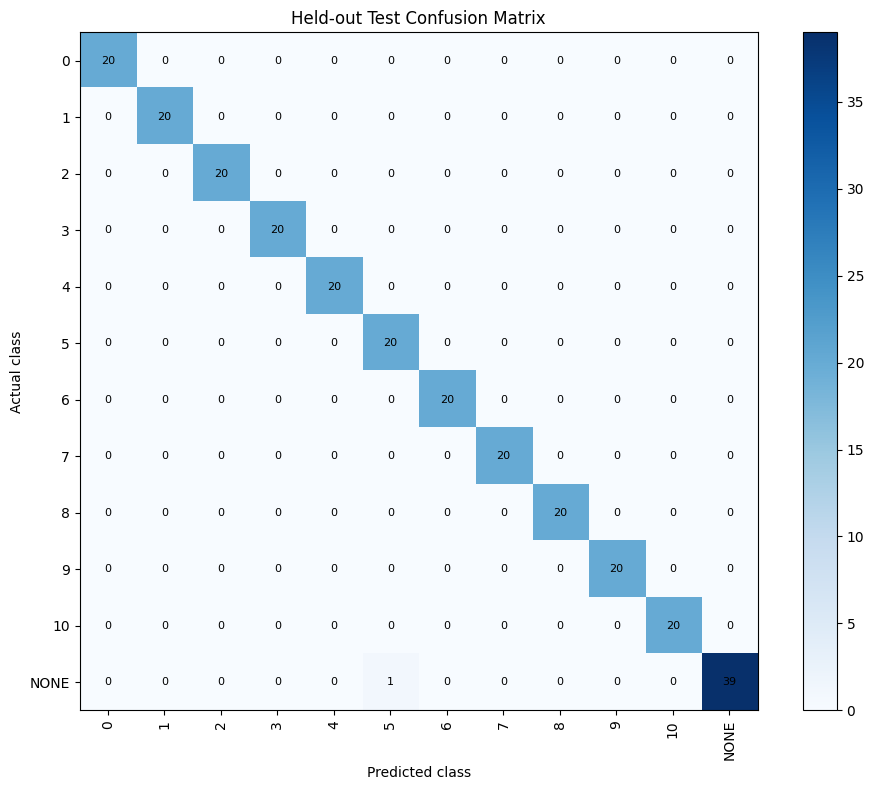

NONE recall: 0.975
NOTE: This measures only the sampled NONE gestures, not every unseen gesture.


In [7]:
# Held-out test evaluation: confusion matrix, per-class precision/recall/F1, and macro/weighted scores.
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
import matplotlib.pyplot as plt

probabilities = motion_model.predict(Xm_test, verbose=0)
y_pred_idx = np.argmax(probabilities, axis=1)
print(classification_report(y_test_idx, y_pred_idx, labels=np.arange(len(MOTION_CLASSES)),
                            target_names=MOTION_CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(y_test_idx, y_pred_idx, labels=np.arange(len(MOTION_CLASSES)))
fig, ax = plt.subplots(figsize=(max(10, len(MOTION_CLASSES)*0.55), max(8, len(MOTION_CLASSES)*0.5)))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(MOTION_CLASSES)), MOTION_CLASSES, rotation=90)
ax.set_yticks(range(len(MOTION_CLASSES)), MOTION_CLASSES)
ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class')
ax.set_title('Held-out Test Confusion Matrix')
fig.colorbar(image, ax=ax)
if len(MOTION_CLASSES) <= 15:
    for row in range(len(MOTION_CLASSES)):
        for col in range(len(MOTION_CLASSES)):
            ax.text(col, row, str(cm[row, col]), ha='center', va='center', fontsize=8)
plt.tight_layout(); plt.show()

# NONE recall: of true NONE examples, what fraction was rejected as NONE?
none_idx = MOTION_CLASSES.index('NONE')
none_mask = (y_test_idx == none_idx)
print('NONE recall:', np.mean(y_pred_idx[none_mask] == none_idx))
print('NOTE: This measures only the sampled NONE gestures, not every unseen gesture.')


### Number Model Export

In [8]:
# %%
motion_model.export("number_model")
print("Number SavedModel export complete!")

# In Google Colab, convert this the same way you convert the static model,
# just pointed at the motion folders so it doesn't overwrite the static tfjs export:
# !tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model number_model tfjs_number_model
# Export class order for web/mobile inference; the last output is NONE.
import json
with open("number_labels.json", "w", encoding="utf-8") as file:
    json.dump(MOTION_CLASSES, file, ensure_ascii=False, indent=2)
print('Exported labels:', MOTION_CLASSES)


INFO:tensorflow:Assets written to: number_model/assets


INFO:tensorflow:Assets written to: number_model/assets


Saved artifact at 'number_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24, 64), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  133544014544336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133544014544144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152880144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152878992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152879184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152880528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152879952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133543152878032: TensorSpec(shape=(), dtype=tf.resource, name=None)
Number SavedModel export complete!
Exported labels: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', 'NONE']
